# X-Ray Projections -- Exact

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch08/ch08-02.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Parallel-Ray Projection

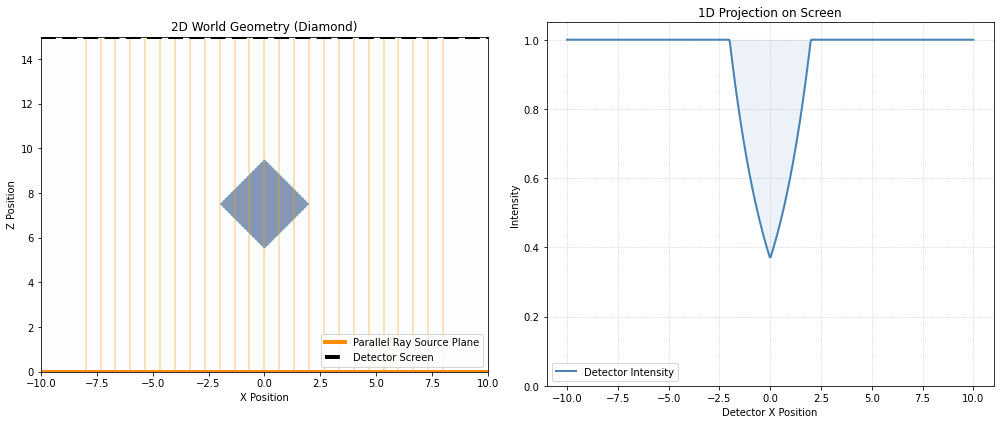

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Parameters ---
shape = 'diamond'  # Options: 'square', 'circle', 'diamond', 'plus', 'diagonal'

w = 4.0     # Width/Diameter of the shape
a = 1.0     # Arm thickness for 'plus' and 'diagonal'
z0 = 7.5    # Z-center of the object
mu_a = 0.25 # Attenuation coefficient
I0 = 1.0    # Initial intensity (Parallel rays have no geometric falloff)

# --- 2. Setup the Grid ---
N = 500
x = np.linspace(-10, 10, N)
z = np.linspace(0, 15, N)
xx, zz = np.meshgrid(x, z)

# --- 3. Exact Mathematical 1D Path Length L(x) ---
# We calculate the exact analytic path length through the 2D slice for any given x.
if shape == 'square':
    L_eff = np.where(np.abs(x) <= w/2, w, 0.0)

elif shape == 'circle':
    val = (w/2)**2 - x**2
    L_eff = np.where(val > 0, 2 * np.sqrt(np.maximum(val, 0)), 0.0)

elif shape == 'diamond':
    val = w/2 - np.abs(x)
    L_eff = np.where(val > 0, 2 * val, 0.0)

elif shape == 'plus':
    # Vertical arm (thickness w) + Horizontal arm (thickness a)
    L_eff = np.where(np.abs(x) <= a/2, w, np.where(np.abs(x) <= w/2, a, 0.0))

elif shape == 'diagonal':
    # Arm 1 (Top-Left to Bottom-Right, rotated 45 degrees)
    z1_in = np.maximum(x - a/np.sqrt(2), -x - w/np.sqrt(2))
    z1_out = np.minimum(x + a/np.sqrt(2), -x + w/np.sqrt(2))
    L1 = np.maximum(0, z1_out - z1_in)

    # Arm 2 (Bottom-Left to Top-Right, rotated -45 degrees)
    z2_in = np.maximum(x - w/np.sqrt(2), -x - a/np.sqrt(2))
    z2_out = np.minimum(x + w/np.sqrt(2), -x + a/np.sqrt(2))
    L2 = np.maximum(0, z2_out - z2_in)

    # Calculate overlapping interval to prevent double-counting the center intersection
    z_overlap_in = np.maximum(z1_in, z2_in)
    z_overlap_out = np.minimum(z1_out, z2_out)
    L_overlap = np.maximum(0, z_overlap_out - z_overlap_in)

    L_eff = L1 + L2 - L_overlap

else:
    raise ValueError("Invalid shape selected.")

# Final Intensity Function on the Detector
Id = I0 * np.exp(-mu_a * L_eff)


# --- 4. 2D World Mask for Visualization ---
# (This is purely for drawing the schematic on the left plot)
if shape == 'square':
    mask = (np.abs(xx) <= w/2) & (np.abs(zz - z0) <= w/2)
elif shape == 'circle':
    mask = (xx**2 + (zz - z0)**2) <= (w/2)**2
elif shape == 'diamond':
    mask = (np.abs(xx) + np.abs(zz - z0)) <= w/2
elif shape == 'plus':
    mask = ((np.abs(xx) <= w/2) & (np.abs(zz - z0) <= a/2)) | \
           ((np.abs(xx) <= a/2) & (np.abs(zz - z0) <= w/2))
elif shape == 'diagonal':
    xp = (xx - (zz - z0)) / np.sqrt(2)
    yp = (xx + (zz - z0)) / np.sqrt(2)
    mask = ((np.abs(xp) <= w/2) & (np.abs(yp) <= a/2)) | \
           ((np.abs(xp) <= a/2) & (np.abs(yp) <= w/2))

# --- 5. Plotting ---
fig1, axes1 = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: 2D X-Z World
axes1[0].imshow(
    mask, extent=[-10, 10, 0, 15], origin='lower', cmap='Blues', alpha=0.5
)

# Draw a sample of the Parallel Rays
ray_x_positions = np.linspace(-8, 8, 25)
for rx in ray_x_positions:
    axes1[0].axvline(rx, color='orange', linewidth=1.5, alpha=0.4)
    
# Draw Source and Detector lines
axes1[0].axhline(0, color='darkorange', linewidth=4, label='Parallel Ray Source Plane')
axes1[0].axhline(15, color='black', linewidth=4, linestyle='--', label='Detector Screen')

axes1[0].set_title(f'2D World Geometry ({shape.capitalize()})')
axes1[0].set_xlabel('X Position')
axes1[0].set_ylabel('Z Position')
axes1[0].legend(loc='lower right')

# Plot 2: 1D Detector Intensity
axes1[1].plot(x, Id, color='steelblue', linewidth=2, label='Detector Intensity')
axes1[1].fill_between(x, Id, 1.0, color='steelblue', alpha=0.1)

axes1[1].set_title(f'1D Projection on Screen')
axes1[1].set_xlabel('Detector X Position')
axes1[1].set_ylabel('Intensity')
axes1[1].set_ylim([0, 1.05])
axes1[1].grid(True, linestyle=':', alpha=0.7)
axes1[1].legend()

plt.tight_layout()
plt.show()

## Radial Projection

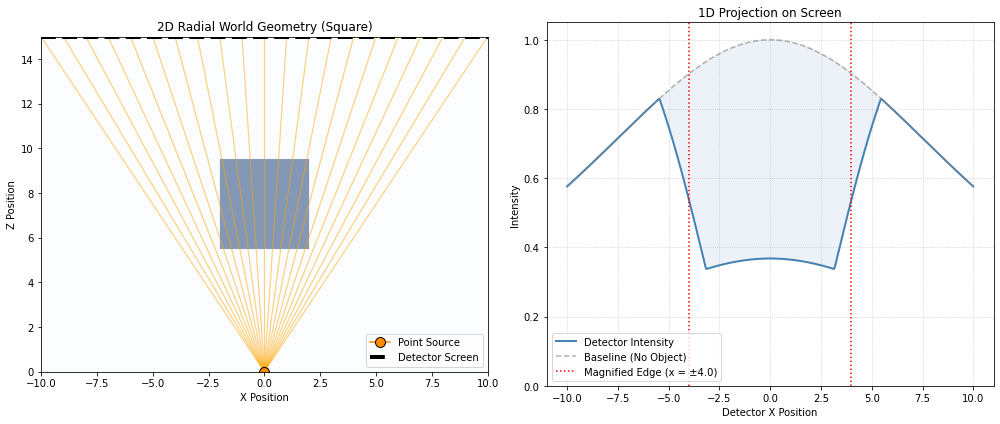

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Parameters ---
shape2 = 'square'  # Options: 'square', 'circle', 'diamond', 'plus', 'diagonal'

w2 = 4.0     # Width/Diameter of the shape2
a2 = 1.0     # Arm thickness for 'plus' and 'diagonal'
z0_2 = 7.5    # Z-center of the object
z_det = 15.0 # Z-location of the detector screen
mu_a2 = 0.25 # Attenuation coefficient

# --- 2. Setup the Grid ---
N2 = 500
x2 = np.linspace(-10, 10, N2)   # Detector X coordinates
z2 = np.linspace(0, z_det, N2)
xx2, zz2 = np.meshgrid(x2, z2)

# --- 3. Exact Mathematical Path Length L_eff2(x2) ---
# For a2 ray originating at (0,0) and hitting detector at (x2, z_det):
# Its slope is m = x2 / z_det. The ray equation is x2(z2) = m * z2
m = x2 / z_det

# The true distance a2 ray travels for every 1 unit of Z is 1/cos(theta)
ray_length_factor = np.sqrt(1 + m**2)

# Baseline Intensity: Inverse Square + Obliquity = cos^3(theta)
I0_2 = (1 / ray_length_factor)**3

# Safe denominators to prevent division by zero
m_safe = np.where(m == 0, 1e-9, m)
mp1_safe = np.where(m + 1 == 0, 1e-9, m + 1)
mm1_safe = np.where(1 - m == 0, 1e-9, 1 - m)

# Helper function: Finds Z-entry and Z-exit of a2 ray through a2 rectangle
def get_z_interval_rect(m_slope, w_x, w_z):
    z_x1, z_x2 = (-w_x/2) / m_slope, (w_x/2) / m_slope
    z_in = np.maximum(np.minimum(z_x1, z_x2), z0_2 - w_z/2)
    z_out = np.minimum(np.maximum(z_x1, z_x2), z0_2 + w_z/2)
    return z_in, z_out

# Helper function: Finds Z-entry and Z-exit of a2 ray through a2 rotated 45-deg rectangle
def get_z_interval_rotated(m_slope, w_u, w_v):
    z_u1, z_u2 = (z0_2 - w_u/np.sqrt(2)) / mp1_safe, (z0_2 + w_u/np.sqrt(2)) / mp1_safe
    z_v1, z_v2 = (z0_2 - w_v/np.sqrt(2)) / mm1_safe, (z0_2 + w_v/np.sqrt(2)) / mm1_safe
    z_in = np.maximum(np.minimum(z_u1, z_u2), np.minimum(z_v1, z_v2))
    z_out = np.minimum(np.maximum(z_u1, z_u2), np.maximum(z_v1, z_v2))
    return z_in, z_out

# Calculate Z-thickness traversed, then multiply by ray_length_factor for true Slant Length
if shape2 == 'square':
    z_in, z_out = get_z_interval_rect(m_safe, w2, w2)
    L_eff2 = np.maximum(0, z_out - z_in) * ray_length_factor

elif shape2 == 'circle':
    A = 1 + m**2
    B = -2 * z0_2
    C = z0_2**2 - (w2/2)**2
    Discriminant = B**2 - 4*A*C
    delta_z = np.where(Discriminant > 0, np.sqrt(np.maximum(0, Discriminant)) / A, 0.0)
    L_eff2 = delta_z * ray_length_factor

elif shape2 == 'diamond':
    z_in, z_out = get_z_interval_rotated(m, w2/np.sqrt(2), w2/np.sqrt(2))
    L_eff2 = np.maximum(0, z_out - z_in) * ray_length_factor

elif shape2 == 'plus':
    z1_in2, z1_out2 = get_z_interval_rect(m_safe, a2, w2) # Vertical arm
    z2_in2, z2_out2 = get_z_interval_rect(m_safe, w2, a2) # Horizontal arm
    overlap = np.maximum(0, np.minimum(z1_out2, z2_out2) - np.maximum(z1_in2, z2_in2))
    L_eff2 = (np.maximum(0, z1_out2 - z1_in2) + np.maximum(0, z2_out2 - z2_in2) - overlap) * ray_length_factor

elif shape2 == 'diagonal':
    z1_in2, z1_out2 = get_z_interval_rotated(m, a2, w2) # Rotated arm 1
    z2_in2, z2_out2 = get_z_interval_rotated(m, w2, a2) # Rotated arm 2
    overlap = np.maximum(0, np.minimum(z1_out2, z2_out2) - np.maximum(z1_in2, z2_in2))
    L_eff2 = (np.maximum(0, z1_out2 - z1_in2) + np.maximum(0, z2_out2 - z2_in2) - overlap) * ray_length_factor

else:
    raise ValueError("Invalid shape selected.")

# Final Intensity Function on the Detector
Id2 = I0_2 * np.exp(-mu_a2 * L_eff2)


# --- 4. 2D World Mask for Visualization ---
if shape2 == 'square':
    mask2 = (np.abs(xx2) <= w2/2) & (np.abs(zz2 - z0_2) <= w2/2)
elif shape2 == 'circle':
    mask2 = (xx2**2 + (zz2 - z0_2)**2) <= (w2/2)**2
elif shape2 == 'diamond':
    mask2 = (np.abs(xx2) + np.abs(zz2 - z0_2)) <= w2/2
elif shape2 == 'plus':
    mask2 = ((np.abs(xx2) <= w2/2) & (np.abs(zz2 - z0_2) <= a2/2)) | \
           ((np.abs(xx2) <= a2/2) & (np.abs(zz2 - z0_2) <= w2/2))
elif shape2 == 'diagonal':
    xp2 = (xx2 - (zz2 - z0_2)) / np.sqrt(2)
    yp2 = (xx2 + (zz2 - z0_2)) / np.sqrt(2)
    mask2 = ((np.abs(xp2) <= w2/2) & (np.abs(yp2) <= a2/2)) | \
           ((np.abs(xp2) <= a2/2) & (np.abs(yp2) <= w2/2))

# --- 5. Plotting ---
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: 2D X-Z World
axes2[0].imshow(
    mask2, extent=[-10, 10, 0, z_det], origin='lower', cmap='Blues', alpha=0.5
)

# Draw Radial Rays emanating from the source
ray_x_positions2 = np.linspace(-10, 10, 21)
for rx in ray_x_positions2:
    axes2[0].plot([0, rx], [0, z_det], color='orange', linewidth=1.2, alpha=0.5)
    
# Draw Point Source and Detector line
axes2[0].plot(0, 0, marker='o', color='darkorange', markersize=10, markeredgecolor='black', label='Point Source')
axes2[0].axhline(z_det, color='black', linewidth=4, linestyle='--', label='Detector Screen')

axes2[0].set_title(f'2D Radial World Geometry ({shape2.capitalize()})')
axes2[0].set_xlabel('X Position')
axes2[0].set_ylabel('Z Position')
axes2[0].legend(loc='lower right')

# Plot 2: 1D Detector Intensity
axes2[1].plot(x2, Id2, color='steelblue', linewidth=2, label='Detector Intensity')
axes2[1].fill_between(x2, Id2, I0_2, color='steelblue', alpha=0.1)
axes2[1].plot(x2, I0_2, color='gray', linestyle='--', alpha=0.6, label='Baseline (No Object)')

axes2[1].set_title(f'1D Projection on Screen')
axes2[1].set_xlabel('Detector X Position')
axes2[1].set_ylabel('Intensity')
axes2[1].set_ylim([0, 1.05])
axes2[1].grid(True, linestyle=':', alpha=0.7)

# Calculate expected Magnification (M = z_det / z0_2)
M = z_det / z0_2
mag_bound = (w2/2) * M

axes2[1].axvline(mag_bound, color='red', linestyle=':', label=f'Magnified Edge (x = ±{mag_bound:.1f})')
axes2[1].axvline(-mag_bound, color='red', linestyle=':')

axes2[1].legend()

plt.tight_layout()
plt.show()